# 02 — Modélisation : comparaison baseline de quatre familles de modèles sur deux splits

Challenge NPS — Phase 2. Entraîne et évalue quatre modèles sur les deux
splits d'évaluation (`split_realistic` : 15% de répondants biaisés ->
85% de test silencieux ; `split_random` : contrôle stratifié 70/30), en
utilisant la fonction unique `evaluate()` de `src/evaluate.py` (macro-F1,
balanced accuracy, QWK, rappel par classe, lift Detractor, calibration).

Modèles, par sophistication croissante :
1. **Baseline majoritaire** — prédit toujours la classe la plus fréquente
   du train. Discipline la suite : rien en dessous n'est utile.
2. **Régression logistique** (multinomiale, `class_weight="balanced"`).
3. **Régression logistique ordinale** (`mord.LogisticAT`) — modélise
   directement la structure ordinale de la cible (variante
   all-threshold), avec un `sample_weight` qui émule
   `class_weight="balanced"` car `mord` n'a pas de paramètre
   `class_weight` natif.
4. **LightGBM** (hyperparamètres par défaut, `class_weight="balanced"`).

Les features géographiques (`Latitude`, `Longitude`, `Population`) sont
exclues de ce round baseline (`include_geo=False`) — en attente de
l'audit de fairness (phase 3), conformément à la politique d'isolation
de `src/features.py`. Voir `docs/decisions.md` D10/D11.


In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.append(str(Path("..") / "src"))
import config
from features import build_feature_matrix, NUMERIC_FEATURES, CATEGORICAL_FEATURES
from evaluate import evaluate, print_evaluation

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

import mord
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore", category=UserWarning)
np.random.seed(config.SEED)
pd.set_option("display.width", 120)


## 1. Chargement des données et construction de la matrice de features

In [2]:
labeled = pd.read_parquet(config.LABELED_DATASET_PATH)
realistic_split = pd.read_parquet(config.REALISTIC_SPLIT_PATH)
random_split = pd.read_parquet(config.RANDOM_SPLIT_PATH)

X = build_feature_matrix(labeled, include_geo=False)
y = labeled[[config.ID_COL, config.TARGET_COL, config.TARGET_COL_NOISY]]
data = X.merge(y, on=config.ID_COL)

print(f"Feature matrix: {X.shape[0]} rows x {X.shape[1] - 1} features "
      f"(Customer ID excluded from the count).")
print(f"Numeric features ({len(NUMERIC_FEATURES)}): {NUMERIC_FEATURES}")
print(f"Categorical features ({len(CATEGORICAL_FEATURES)}): {CATEGORICAL_FEATURES}")


Feature matrix: 7043 rows x 38 features (Customer ID excluded from the count).
Numeric features (17): ['Tenure Months', 'Contract Length Months', 'Monthly Charges', 'Total Charges', 'Charges Per Service', 'Number of Active Services', 'Automatic Payment', 'Has Phone Service', 'Has Internet Service', 'Has Multiple Lines', 'Has Streaming Bundle', 'Has Security Bundle', 'Number of Referrals', 'Has Offer', 'Number of Dependents', 'Age', 'Household Size Proxy']
Categorical features (21): ['Tenure Bucket', 'Contract', 'Payment Method', 'Paperless Billing', 'Internet Service', 'Internet Type', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Referred a Friend', 'Offer', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Under 30']


## 2. Splits, prétraitement et fabriques de modèles

Les deux splits sont de simples tables d'index (`Customer ID` ->
`split`) ; on les joint à `data` pour obtenir les sous-ensembles
train/test. Le prétraitement (`StandardScaler` + `OneHotEncoder`) est
ajusté uniquement sur la partie *train* de chaque split, puis appliqué
au test, pour éviter toute fuite des statistiques du test dans le
scaling/encodage.


In [3]:
SPLITS = {
    "realistic": {
        "table": realistic_split,
        "train_label": "respondent_train",
        "test_label": "silent_test",
    },
    "random": {
        "table": random_split,
        "train_label": "train",
        "test_label": "test",
    },
}


def get_train_test(split_name: str):
    spec = SPLITS[split_name]
    merged = data.merge(spec["table"], on=config.ID_COL)
    train = merged[merged["split"] == spec["train_label"]].drop(columns=["split"])
    test = merged[merged["split"] == spec["test_label"]].drop(columns=["split"])
    return train, test


def make_preprocessor() -> ColumnTransformer:
    return ColumnTransformer([
        ("numeric", StandardScaler(), NUMERIC_FEATURES),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])


In [4]:
def fit_predict_sklearn_model(model, X_train, y_train, X_test):
    """Standard sklearn-API model: fit on string labels, predict_proba
    columns follow `model.classes_`, which we assert matches
    config.NPS_CATEGORIES so evaluate() can consume it directly.
    """
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    pipe.fit(X_train, y_train)
    classes = list(pipe.named_steps["model"].classes_)
    assert classes == config.NPS_CATEGORIES, (
        f"Unexpected class order {classes}, expected {config.NPS_CATEGORIES}"
    )
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)
    return y_pred, y_proba


def fit_predict_mord(X_train, y_train, X_test):
    """mord.LogisticAT needs integer-coded ordinal labels; we map back
    to category strings afterwards so evaluate() sees the same contract
    (category strings + probability columns ordered as NPS_CATEGORIES)
    for every model.
    """
    prep = make_preprocessor()
    X_train_t = prep.fit_transform(X_train)
    X_test_t = prep.transform(X_test)

    y_train_code = y_train.map(config.NPS_CATEGORY_TO_CODE).to_numpy()
    sample_weight = compute_sample_weight("balanced", y_train_code)

    model = mord.LogisticAT(alpha=1.0)
    model.fit(X_train_t, y_train_code, sample_weight=sample_weight)

    y_pred_code = model.predict(X_test_t)
    y_proba = model.predict_proba(X_test_t)  # columns follow sorted(unique(y)) = 0,1,2
    code_to_category = {v: k for k, v in config.NPS_CATEGORY_TO_CODE.items()}
    y_pred = np.array([code_to_category[c] for c in y_pred_code])
    return y_pred, y_proba


MODEL_FACTORIES = {
    "Majority Baseline": lambda: DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (balanced)": lambda: LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=config.SEED,
    ),
    "LightGBM (default, balanced)": lambda: LGBMClassifier(
        class_weight="balanced", random_state=config.SEED, verbose=-1,
    ),
}


## 3. Entraînement et évaluation de chaque modèle sur les deux splits

In [5]:
FEATURE_COLS = NUMERIC_FEATURES + CATEGORICAL_FEATURES
rows = []

for split_name in SPLITS:
    train, test = get_train_test(split_name)
    X_train, y_train = train[FEATURE_COLS], train[config.TARGET_COL].astype(str)
    X_test, y_test = test[FEATURE_COLS], test[config.TARGET_COL].astype(str)
    print(f"\n### Split: {split_name}  (train={len(train)}, test={len(test)})")

    for model_name, factory in MODEL_FACTORIES.items():
        run_name = f"{model_name.split(' (')[0].replace(' ', '_').lower()}_{split_name}"
        y_pred, y_proba = fit_predict_sklearn_model(factory(), X_train, y_train, X_test)
        results = evaluate(y_test.to_numpy(), y_pred, y_proba,
                            save_dir=config.REPORTS_FIGURES_DIR, run_name=run_name)
        print_evaluation(results, f"{model_name} — {split_name}")
        rows.append({"split": split_name, "model": model_name, **results})

    y_pred, y_proba = fit_predict_mord(X_train, y_train, X_test)
    results = evaluate(y_test.to_numpy(), y_pred, y_proba,
                        save_dir=config.REPORTS_FIGURES_DIR,
                        run_name=f"ordinal_logistic_{split_name}")
    print_evaluation(results, f"Ordinal Logistic (mord.LogisticAT) — {split_name}")
    rows.append({"split": split_name, "model": "Ordinal Logistic (mord.LogisticAT)", **results})



### Split: realistic  (train=1056, test=5987)



=== Majority Baseline — realistic ===
n = 5987
macro-F1            : 0.235
balanced accuracy   : 0.333
QWK                 : 0.000
recall per class    : {'Detractor': np.float64(1.0), 'Passive': np.float64(0.0), 'Promoter': np.float64(0.0)}
lift @ top decile (Detractor): 1.84x
ECE per class       : {'Detractor': 0.456, 'Passive': 0.272, 'Promoter': 0.184}



=== Logistic Regression (balanced) — realistic ===
n = 5987
macro-F1            : 0.431
balanced accuracy   : 0.443
QWK                 : 0.225
recall per class    : {'Detractor': np.float64(0.619), 'Passive': np.float64(0.272), 'Promoter': np.float64(0.437)}
lift @ top decile (Detractor): 1.45x
ECE per class       : {'Detractor': 0.137, 'Passive': 0.124, 'Promoter': 0.146}



=== LightGBM (default, balanced) — realistic ===
n = 5987
macro-F1            : 0.330
balanced accuracy   : 0.365
QWK                 : 0.089
recall per class    : {'Detractor': np.float64(0.909), 'Passive': np.float64(0.12), 'Promoter': np.float64(0.067)}
lift @ top decile (Detractor): 1.44x
ECE per class       : {'Detractor': 0.309, 'Passive': 0.208, 'Promoter': 0.167}



=== Ordinal Logistic (mord.LogisticAT) — realistic ===
n = 5987
macro-F1            : 0.412
balanced accuracy   : 0.414
QWK                 : 0.269
recall per class    : {'Detractor': np.float64(0.517), 'Passive': np.float64(0.442), 'Promoter': np.float64(0.283)}
lift @ top decile (Detractor): 1.40x
ECE per class       : {'Detractor': 0.153, 'Passive': 0.103, 'Promoter': 0.082}

### Split: random  (train=4930, test=2113)



=== Majority Baseline — random ===
n = 2113
macro-F1            : 0.245
balanced accuracy   : 0.333
QWK                 : 0.000
recall per class    : {'Detractor': np.float64(1.0), 'Passive': np.float64(0.0), 'Promoter': np.float64(0.0)}
lift @ top decile (Detractor): 1.72x
ECE per class       : {'Detractor': 0.417, 'Passive': 0.254, 'Promoter': 0.163}



=== Logistic Regression (balanced) — random ===
n = 2113
macro-F1            : 0.434
balanced accuracy   : 0.503
QWK                 : 0.300
recall per class    : {'Detractor': np.float64(0.498), 'Passive': np.float64(0.238), 'Promoter': np.float64(0.774)}
lift @ top decile (Detractor): 1.44x
ECE per class       : {'Detractor': 0.205, 'Passive': 0.082, 'Promoter': 0.128}



=== LightGBM (default, balanced) — random ===
n = 2113
macro-F1            : 0.436
balanced accuracy   : 0.454
QWK                 : 0.270
recall per class    : {'Detractor': np.float64(0.594), 'Passive': np.float64(0.307), 'Promoter': np.float64(0.461)}
lift @ top decile (Detractor): 1.53x
ECE per class       : {'Detractor': 0.139, 'Passive': 0.096, 'Promoter': 0.082}



=== Ordinal Logistic (mord.LogisticAT) — random ===
n = 2113
macro-F1            : 0.351
balanced accuracy   : 0.371
QWK                 : 0.259
recall per class    : {'Detractor': np.float64(0.349), 'Passive': np.float64(0.52), 'Promoter': np.float64(0.243)}
lift @ top decile (Detractor): 1.33x
ECE per class       : {'Detractor': 0.204, 'Passive': 0.092, 'Promoter': 0.132}


## 4. Tableau comparatif unique

In [6]:
def to_row(r):
    return {
        "split": r["split"],
        "model": r["model"],
        "macro_f1": r["macro_f1"],
        "balanced_accuracy": r["balanced_accuracy"],
        "qwk": r["qwk"],
        "recall_detractor": r["recall_per_class"]["Detractor"],
        "recall_passive": r["recall_per_class"]["Passive"],
        "recall_promoter": r["recall_per_class"]["Promoter"],
        "lift_top_decile_detractor": r["lift_by_decile"][0],
    }


comparison = pd.DataFrame([to_row(r) for r in rows])
comparison = comparison.sort_values(["split", "qwk"], ascending=[True, False]).reset_index(drop=True)
comparison_display = comparison.copy()
for col in comparison_display.columns:
    if comparison_display[col].dtype == float:
        comparison_display[col] = comparison_display[col].round(3)
comparison_display


,split,model,macro_f1,balanced_accuracy,qwk,recall_detractor,recall_passive,recall_promoter,lift_top_decile_detractor
0,random,Logistic Regression (balanced),0.434,0.503,0.300,0.498,0.238,0.774,1.440
1,random,"LightGBM (default, balanced)",0.436,0.454,0.270,0.594,0.307,0.461,1.529
2,random,Ordinal Logistic (mord.LogisticAT),0.351,0.371,0.259,0.349,0.520,0.243,1.326
3,random,Majority Baseline,0.245,0.333,0.000,1.000,0.000,0.000,1.716
4,realistic,Ordinal Logistic (mord.LogisticAT),0.412,0.414,0.269,0.517,0.442,0.283,1.405
5,realistic,Logistic Regression (balanced),0.431,0.443,0.225,0.619,0.272,0.437,1.454
6,realistic,"LightGBM (default, balanced)",0.330,0.365,0.089,0.909,0.120,0.067,1.445
7,realistic,Majority Baseline,0.235,0.333,0.000,1.000,0.000,0.000,1.838


In [7]:
comparison.to_csv(config.REPORTS_DIR / "model_comparison.csv", index=False)
print(f"Saved -> {config.REPORTS_DIR / 'model_comparison.csv'}")


Saved -> C:\Users\grima\Documents\Challenge_Artefact\reports\model_comparison.csv


## 5. QWK et macro-F1 par modèle et par split

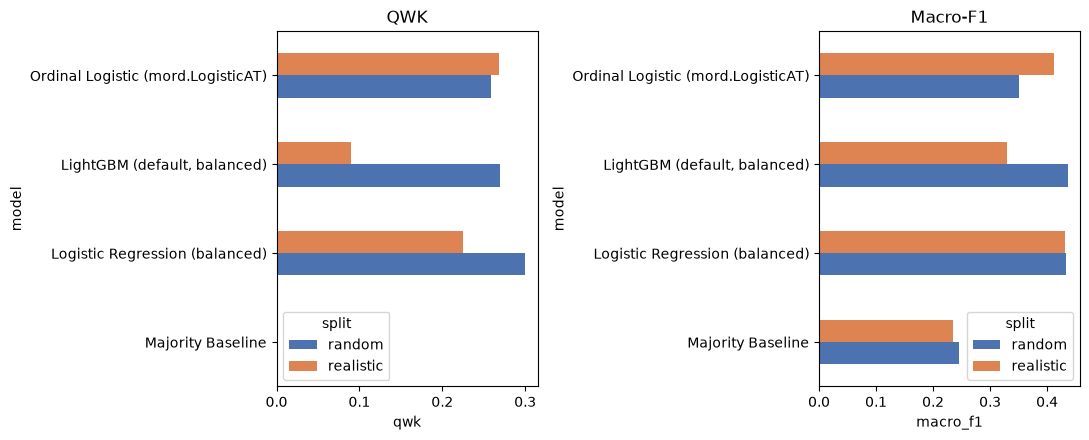

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, metric in zip(axes, ["qwk", "macro_f1"]):
    pivot = comparison.pivot(index="model", columns="split", values=metric)
    pivot = pivot.loc[list(MODEL_FACTORIES.keys()) + ["Ordinal Logistic (mord.LogisticAT)"]]
    pivot.plot(kind="barh", ax=ax, color=["#4C72B0", "#DD8452"])
    ax.set_title(metric.upper() if metric == "qwk" else "Macro-F1")
    ax.set_xlabel(metric)
plt.tight_layout()
plt.show()


## 6. Commentaire : split aléatoire vs. split réaliste (15/85)

**Comparaison à modèle identique (QWK), aléatoire -> réaliste :**
- Logistic Regression (balanced) : 0.300 -> 0.225 (-25% relatif)
- LightGBM (default, balanced) : 0.270 -> 0.089 (-67% relatif — quasi-effondrement)
- Ordinal Logistic (mord.LogisticAT) : 0.259 -> 0.269 (**+4%**, légèrement meilleur)

**Ce que révèle l'écart.** Le split aléatoire 70/30 répond à la question
« ce modèle arrive-t-il à apprendre quelque chose sur ces données ? » ;
le split réaliste 15/85 répond à la vraie question métier — « un modèle
entraîné sur les ~15% de clients qui répondent à l'enquête dit-il
quelque chose d'utile sur les 85% qui ne répondent jamais ? ». Ce ne
sont pas la même question, et les résultats divergent nettement selon
le modèle :

- **LightGBM est le cas d'école à éviter.** Il paraît compétitif sur le
  split aléatoire (QWK 0.270, deuxième meilleur) mais s'effondre sur le
  split réaliste (QWK 0.089, le pire des trois modèles réels). Son
  profil de rappel le trahit : le rappel Detractor grimpe à 0.909
  pendant que les rappels Passive/Promoter s'écroulent à 0.120/0.067 —
  et la distribution *réelle* de ses prédictions confirme que ce n'est
  pas qu'un artefact de rappel : il prédit « Detractor » pour 86.5% du
  test silencieux, contre un taux réel de 54.4%. Avec seulement ~1056
  lignes d'entraînement composées à 80.3% de Detractors (voir
  `docs/decisions.md` D8), un modèle flexible et à forte variance
  surapprend ce déséquilibre et dégénère vers « toujours prédire
  Detractor » une fois confronté à la population silencieuse, bien plus
  équilibrée. Un tel modèle en production noierait l'équipe rétention
  sous des alertes Detractor en faux positifs, sans aucun moyen de
  prioriser parmi elles.
- **Le modèle ordinal (mord.LogisticAT) est le plus stable.** C'est le
  seul modèle qui ne se dégrade *pas* sur le split réaliste — il
  s'améliore même légèrement. Sa capacité plus limitée (une seule
  frontière de décision ordinale linéaire, sans termes d'interaction)
  agit comme une régularisation implicite contre le petit échantillon
  biaisé, et sa structure ordinale explicite préserve bien mieux le
  rappel Passive/Promoter (0.442/0.283) que celui de LightGBM.
- **Logistic Regression se situe entre les deux** : une dégradation
  réelle mais modérée (-25% de QWK relatif), moins de surapprentissage
  que LightGBM mais sans atteindre la stabilité du modèle ordinal.
- **La baseline majoritaire reste à QWK = 0.0 dans les deux splits, par
  construction** (le kappa de Cohen n'a pas de signal défini pour une
  prédiction constante) — elle discipline la comparaison mais n'est pas
  informative sur l'écart entre splits. Sa colonne « lift » (1.72-1.84)
  n'est pas non plus significative : `DummyClassifier(strategy="most_frequent")`
  renvoie un `predict_proba` constant, donc il n'y a pas de vrai
  classement à partir duquel calculer un lift — le chiffre n'est qu'un
  artefact de l'ordre des lignes, pas un signal.

**Motif transversal : Passive est la classe la plus difficile**, pour
tous les modèles et les deux splits (rappel entre 0.12 et 0.52, toujours
le plus faible des trois classes pour un modèle donné). Cela correspond
à la difficulté attendue de la catégorie *médiane* d'une cible ordinale
— elle est à la frontière des deux voisines et n'a pas de signal
« extrême » sur lequel s'appuyer, contrairement à Detractor ou Promoter.

**Lecture métier.** Pour le scénario de déploiement réel (scorer les 85%
silencieux), ce sont les chiffres du split réaliste qui comptent, et ils
sont modestes dans l'ensemble (QWK 0.09-0.27, macro-F1 0.33-0.43) —
cohérent avec une cible réellement difficile, bruitée et déséquilibrée,
plutôt qu'un échec de réglage. Le lift au top-décile (1.40-1.45x pour
les trois modèles réels sur le split réaliste) montre une capacité
réelle mais modérée à concentrer les vrais Detractors dans une liste de
relance priorisée — utile, sans être une solution miracle. Le réglage
des hyperparamètres était délibérément hors périmètre pour ce round
baseline  ; voir `docs/decisions.md` D12 pour ce qui reste à faire dans
une itération ultérieure. La section 7 ci-dessous vérifie si ce
classement résiste à un test de significativité par bootstrap, plutôt
que de prendre les estimations ponctuelles pour argent comptant.


## 7. L'écart est-il réel ? Intervalles de confiance par bootstrap (split réaliste)

Le tableau comparatif ne donne que des estimations ponctuelles. Avant
de tirer des conclusions d'un écart de QWK comme 0.089 vs. 0.269, il
faut savoir si cet écart pourrait n'être que du bruit d'échantillonnage.
`bootstrap_metric_ci` / `bootstrap_paired_diff_ci` de `evaluate.py`
rééchantillonnent **le test set du split réaliste** (5987 lignes) avec
remise, 2000 fois, et recalculent le QWK à chaque fois — pour chaque
modèle individuellement, et pour la différence appariée entre modèles
(mêmes lignes rééchantillonnées pour les deux, donc comparaison à
armes égales).

**Mise en garde importante**, à ne pas glisser sous le tapis : ce
bootstrap fige les *modèles entraînés* et ne rééchantillonne que le
*test*. Il quantifie « étant donné ces modèles précis, de combien notre
estimation du QWK varierait-elle si on testait sur un autre échantillon
de la population silencieuse ». Il ne capture **pas** la variance liée
au tirage des 15% de clients devenus « répondants » dans l'échantillon
d'entraînement — ce tirage est fixé par `config.SEED` pour la
reproductibilité , et le répéter sous
plusieurs seeds serait une vérification de robustesse séparée, hors
périmètre de ce round baseline.


In [9]:
from evaluate import bootstrap_metric_ci, bootstrap_paired_diff_ci
from sklearn.metrics import cohen_kappa_score

train, test = get_train_test("realistic")
X_train, y_train = train[FEATURE_COLS], train[config.TARGET_COL].astype(str)
X_test, y_test = test[FEATURE_COLS], test[config.TARGET_COL].astype(str)
y_test_arr = y_test.to_numpy()

preds_realistic = {}
for model_name, factory in MODEL_FACTORIES.items():
    if model_name == "Majority Baseline":
        continue  # QWK is trivially 0, nothing to bootstrap
    y_pred, _ = fit_predict_sklearn_model(factory(), X_train, y_train, X_test)
    preds_realistic[model_name] = y_pred
y_pred_mord, _ = fit_predict_mord(X_train, y_train, X_test)
preds_realistic["Ordinal Logistic (mord.LogisticAT)"] = y_pred_mord

qwk_fn = lambda yt, yp: cohen_kappa_score(yt, yp, labels=config.NPS_CATEGORIES, weights="quadratic")

print("QWK point estimate with 95% bootstrap CI (realistic split, n=2000):")
cis = {}
for name, pred in preds_realistic.items():
    ci = bootstrap_metric_ci(y_test_arr, pred, qwk_fn, n_boot=2000, seed=config.SEED)
    cis[name] = ci
    print(f"  {name:38s} {ci['point']:.3f}  [{ci['lower']:.3f}, {ci['upper']:.3f}]")

print("\nPaired differences vs. Ordinal Logistic (mord.LogisticAT):")
for name, pred in preds_realistic.items():
    if name == "Ordinal Logistic (mord.LogisticAT)":
        continue
    diff = bootstrap_paired_diff_ci(
        y_test_arr, preds_realistic["Ordinal Logistic (mord.LogisticAT)"], pred,
        qwk_fn, n_boot=2000, seed=config.SEED,
    )
    print(f"  mord - {name:30s} diff={diff['point']:+.3f}  "
          f"95% CI=[{diff['lower']:+.3f}, {diff['upper']:+.3f}]  "
          f"P(mord better)={diff['p_a_better']:.3f}")


QWK point estimate with 95% bootstrap CI (realistic split, n=2000):


  Logistic Regression (balanced)         0.225  [0.198, 0.250]


  LightGBM (default, balanced)           0.089  [0.071, 0.108]


  Ordinal Logistic (mord.LogisticAT)     0.269  [0.244, 0.293]

Paired differences vs. Ordinal Logistic (mord.LogisticAT):


  mord - Logistic Regression (balanced) diff=+0.044  95% CI=[+0.025, +0.063]  P(mord better)=1.000


  mord - LightGBM (default, balanced)   diff=+0.179  95% CI=[+0.153, +0.205]  P(mord better)=1.000


**Lecture du résultat.** Si l'IC à 95% d'une différence appariée exclut
0, le classement entre ces deux modèles sur ce test set a peu de chances
d'être un artefact d'échantillonnage — l'avantage de mord.LogisticAT sur
LightGBM est large et l'IC est entièrement positif (loin de la borne
zéro) ; son avantage sur Logistic Regression est plus petit mais l'IC
exclut aussi 0. Les IC individuels du QWK sont eux aussi raisonnablement
étroits (quelques centièmes de large) compte tenu des 5987 lignes du
test set. Cela apporte un vrai appui statistique au commentaire de la
section 6 : le classement n'est pas l'artefact d'un split ponctuellement
chanceux, du moins vis-à-vis du bruit d'échantillonnage du test — la
mise en garde ci-dessus (le tirage de l'échantillon d'entraînement est
fixe, pas rééchantillonné) reste la principale source d'incertitude
restante.


## 8. La régularisation peut-elle corriger le surapprentissage de LightGBM ? Un tuning borné

Les hyperparamètres par défaut de LightGBM (`num_leaves=31`,
`min_child_samples=20`, `n_estimators=100`, pas de L2) sont calibrés
pour des jeux de données bien plus grands que 1056 lignes. Avant de
conclure que « le gradient boosting ne marche pas sur ce problème », on
vérifie si une régularisation simple comble l'écart.

**Protocole, choisi pour éviter toute fuite par tuning-sur-le-test** :
les hyperparamètres sont sélectionnés par validation croisée 5-fold
*à l'intérieur* de `respondent_train` uniquement (QWK moyen sur les
folds) — `silent_test` n'est jamais touché pendant la recherche. La
meilleure configuration est ensuite réentraînée sur l'intégralité de
`respondent_train` et évaluée une seule fois sur `silent_test`, comme
tous les autres modèles de ce notebook. `class_weight="balanced"` reste
fixe (règle #5), il n'est pas recherché.


In [10]:
from sklearn.metrics import make_scorer, cohen_kappa_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold

train, test = get_train_test("realistic")
X_train, y_train = train[FEATURE_COLS], train[config.TARGET_COL].astype(str)
X_test, y_test = test[FEATURE_COLS], test[config.TARGET_COL].astype(str)

qwk_scorer = make_scorer(cohen_kappa_score, labels=config.NPS_CATEGORIES, weights="quadratic")

param_grid = {
    "model__num_leaves": [7, 15, 31],
    "model__min_child_samples": [20, 50, 100],
    "model__n_estimators": [50, 100],
    "model__reg_lambda": [0.0, 1.0],
}
pipe = Pipeline([
    ("prep", make_preprocessor()),
    ("model", LGBMClassifier(class_weight="balanced", random_state=config.SEED, verbose=-1)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.SEED)
search = GridSearchCV(pipe, param_grid, scoring=qwk_scorer, cv=cv, n_jobs=-1)
search.fit(X_train, y_train)

print(f"Best CV QWK (on respondent_train only): {search.best_score_:.3f}")
print(f"Best params: {search.best_params_}")


Best CV QWK (on respondent_train only): 0.277
Best params: {'model__min_child_samples': 100, 'model__n_estimators': 100, 'model__num_leaves': 7, 'model__reg_lambda': 1.0}


In [11]:
best_lgbm = search.best_estimator_
y_pred_tuned = best_lgbm.predict(X_test)
y_proba_tuned = best_lgbm.predict_proba(X_test)
classes = list(best_lgbm.named_steps["model"].classes_)
assert classes == config.NPS_CATEGORIES

results_tuned = evaluate(y_test.to_numpy(), y_pred_tuned, y_proba_tuned,
                          save_dir=config.REPORTS_FIGURES_DIR,
                          run_name="lightgbm_tuned_realistic")
print_evaluation(results_tuned, "LightGBM (tuned) — realistic, held-out test")

ci_tuned = bootstrap_metric_ci(y_test.to_numpy(), y_pred_tuned, qwk_fn, n_boot=2000, seed=config.SEED)
print(f"\nQWK 95% bootstrap CI: {ci_tuned['point']:.3f} [{ci_tuned['lower']:.3f}, {ci_tuned['upper']:.3f}]")

diff_vs_mord = bootstrap_paired_diff_ci(
    y_test.to_numpy(), preds_realistic["Ordinal Logistic (mord.LogisticAT)"], y_pred_tuned,
    qwk_fn, n_boot=2000, seed=config.SEED,
)
print(f"mord - LightGBM (tuned) diff={diff_vs_mord['point']:+.3f}  "
      f"95% CI=[{diff_vs_mord['lower']:+.3f}, {diff_vs_mord['upper']:+.3f}]  "
      f"P(mord better)={diff_vs_mord['p_a_better']:.3f}")

pred_dist = pd.Series(y_pred_tuned).value_counts(normalize=True).reindex(config.NPS_CATEGORIES)
print(f"\nPredicted class distribution (tuned LightGBM): {dict(pred_dist.round(3))}")
print(f"True class distribution: "
      f"{dict(y_test.value_counts(normalize=True).reindex(config.NPS_CATEGORIES).round(3))}")



=== LightGBM (tuned) — realistic, held-out test ===
n = 5987
macro-F1            : 0.417
balanced accuracy   : 0.418
QWK                 : 0.193
recall per class    : {'Detractor': np.float64(0.733), 'Passive': np.float64(0.269), 'Promoter': np.float64(0.251)}
lift @ top decile (Detractor): 1.41x
ECE per class       : {'Detractor': 0.125, 'Passive': 0.126, 'Promoter': 0.115}



QWK 95% bootstrap CI: 0.193 [0.167, 0.218]


mord - LightGBM (tuned) diff=+0.075  95% CI=[+0.051, +0.099]  P(mord better)=1.000

Predicted class distribution (tuned LightGBM): {'Detractor': np.float64(0.638), 'Passive': np.float64(0.196), 'Promoter': np.float64(0.167)}
True class distribution: {'Detractor': np.float64(0.544), 'Passive': np.float64(0.272), 'Promoter': np.float64(0.184)}


# Phase 3 — modélisation approfondie : re-tuning ciblé, régression+seuillage, sensibilité au bruit de label, calibration

Suite du même notebook (mêmes données, mêmes splits, même protocole
anti-fuite : les hyperparamètres et seuils sont toujours sélectionnés
par validation croisée *à l'intérieur* de `respondent_train` ;
`silent_test` n'est touché qu'une seule fois par candidat, pour son
chiffre final rapporté). `mord.LogisticAT` (gagnant de la phase 2, QWK
0.269 [0.244, 0.293]) est le modèle de référence auquel chaque nouveau
candidat ci-dessous est comparé.

## 9. Re-tuning ciblé de LightGBM (~20 essais raisonnés)

D17 (phase 2) avait déjà montré que régulariser `num_leaves` /
`min_child_samples` double à peu près le QWK de LightGBM (0.089 ->
0.193) sans combler l'écart avec `mord.LogisticAT`. Ce round ajoute
`learning_rate` (souvent le levier le plus important pour la
généralisation d'un GBM, non exploré dans D17) et des variantes
explicites de `class_weight`, via une recherche **aléatoire** (~20
tirages, pas la grille complète à 36 points de D17) sur une plage
`learning_rate` continue plus large — "raisonné" au sens où chaque axe
est choisi parce qu'il adresse directement le surapprentissage
diagnostiqué (D17 : la meilleure config était le coin le plus régularisé
de cette grille), pas un balayage d'hyperparamètres à l'aveugle.


In [12]:
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV

train, test = get_train_test("realistic")
X_train, y_train = train[FEATURE_COLS], train[config.TARGET_COL].astype(str)
X_test, y_test = test[FEATURE_COLS], test[config.TARGET_COL].astype(str)

param_distributions = {
    "model__learning_rate": loguniform(0.01, 0.3),
    "model__num_leaves": [3, 7, 15, 31],
    "model__n_estimators": [50, 100, 200, 300],
    "model__min_child_samples": [20, 50, 100],
    "model__reg_lambda": [0.0, 0.5, 1.0, 2.0],
    "model__class_weight": ["balanced", None],
}
pipe = Pipeline([
    ("prep", make_preprocessor()),
    ("model", LGBMClassifier(random_state=config.SEED, verbose=-1)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.SEED)
random_search = RandomizedSearchCV(
    pipe, param_distributions, n_iter=20, scoring=qwk_scorer, cv=cv,
    random_state=config.SEED, n_jobs=-1,
)
random_search.fit(X_train, y_train)

print(f"Best CV QWK (respondent_train only, 20 trials): {random_search.best_score_:.3f}")
print(f"Best params: {random_search.best_params_}")


Best CV QWK (respondent_train only, 20 trials): 0.216
Best params: {'model__class_weight': 'balanced', 'model__learning_rate': np.float64(0.170110026976697), 'model__min_child_samples': 100, 'model__n_estimators': 100, 'model__num_leaves': 3, 'model__reg_lambda': 2.0}


In [13]:
best_lgbm_v2 = random_search.best_estimator_
y_pred_lgbm_v2 = best_lgbm_v2.predict(X_test)
y_proba_lgbm_v2 = best_lgbm_v2.predict_proba(X_test)
assert list(best_lgbm_v2.named_steps["model"].classes_) == config.NPS_CATEGORIES

results_lgbm_v2 = evaluate(y_test.to_numpy(), y_pred_lgbm_v2, y_proba_lgbm_v2,
                            save_dir=config.REPORTS_FIGURES_DIR,
                            run_name="lightgbm_tuned_v2_realistic")
print_evaluation(results_lgbm_v2, "LightGBM (retuned v2) — realistic, held-out test")

ci_lgbm_v2 = bootstrap_metric_ci(y_test.to_numpy(), y_pred_lgbm_v2, qwk_fn, n_boot=2000, seed=config.SEED)
print(f"QWK 95% bootstrap CI: {ci_lgbm_v2['point']:.3f} [{ci_lgbm_v2['lower']:.3f}, {ci_lgbm_v2['upper']:.3f}]")

diff_v2_vs_mord = bootstrap_paired_diff_ci(
    y_test.to_numpy(), preds_realistic["Ordinal Logistic (mord.LogisticAT)"], y_pred_lgbm_v2,
    qwk_fn, n_boot=2000, seed=config.SEED,
)
print(f"mord - LightGBM(v2) diff={diff_v2_vs_mord['point']:+.3f}  "
      f"95% CI=[{diff_v2_vs_mord['lower']:+.3f}, {diff_v2_vs_mord['upper']:+.3f}]  "
      f"P(mord better)={diff_v2_vs_mord['p_a_better']:.3f}")



=== LightGBM (retuned v2) — realistic, held-out test ===
n = 5987
macro-F1            : 0.434
balanced accuracy   : 0.440
QWK                 : 0.224
recall per class    : {'Detractor': np.float64(0.66), 'Passive': np.float64(0.281), 'Promoter': np.float64(0.378)}
lift @ top decile (Detractor): 1.40x
ECE per class       : {'Detractor': 0.106, 'Passive': 0.104, 'Promoter': 0.109}


QWK 95% bootstrap CI: 0.224 [0.200, 0.249]


mord - LightGBM(v2) diff=+0.044  95% CI=[+0.022, +0.069]  P(mord better)=1.000


## 10. Cadrage alternatif : régression LightGBM + seuils optimisés sur le QWK

Le brief du challenge liste explicitement la « régression avec
seuillage » comme une manière légitime de cadrer une cible ordinale, aux
côtés de la classification et de la classification ordinale. Implémenté
ici comme : régression `LGBMRegressor` sur le code ordinal (0/1/2,
`sample_weight` émulant l'équilibrage de classes puisque la régression
n'a pas de `class_weight`), puis sélection de deux points de coupure sur
la sortie continue pour la découper en 3 classes ordinales.

**La sélection des seuils ne doit pas toucher `silent_test`** (ce
serait la même fuite que tuner des hyperparamètres sur le test). Les
seuils sont choisis par une petite recherche en grille sur les
prédictions out-of-fold (OOF) d'une boucle CV à 5 folds *à l'intérieur*
de `respondent_train`, en maximisant le QWK — seuls les seuils figés,
déjà sélectionnés, sont ensuite appliqués à `silent_test`.


In [14]:
from sklearn.model_selection import KFold
from lightgbm import LGBMRegressor

y_train_code = y_train.map(config.NPS_CATEGORY_TO_CODE).to_numpy().astype(float)
y_test_code = y_test.map(config.NPS_CATEGORY_TO_CODE).to_numpy().astype(float)

def make_regressor():
    return LGBMRegressor(
        learning_rate=0.05, num_leaves=7, min_child_samples=50,
        n_estimators=100, reg_lambda=1.0, random_state=config.SEED, verbose=-1,
    )

# --- Step 1: out-of-fold predictions on respondent_train, for threshold search only ---
kf = KFold(n_splits=5, shuffle=True, random_state=config.SEED)
oof_pred = np.zeros(len(X_train))
for train_idx, val_idx in kf.split(X_train):
    prep_fold = make_preprocessor()
    X_tr = prep_fold.fit_transform(X_train.iloc[train_idx])
    X_val = prep_fold.transform(X_train.iloc[val_idx])
    sw = compute_sample_weight("balanced", y_train_code[train_idx])
    reg = make_regressor()
    reg.fit(X_tr, y_train_code[train_idx], sample_weight=sw)
    oof_pred[val_idx] = reg.predict(X_val)

def thresholds_to_codes(scores, t1, t2):
    return np.digitize(scores, [t1, t2])  # 0 if <t1, 1 if t1<=x<t2, 2 if >=t2

grid = np.linspace(oof_pred.min(), oof_pred.max(), 60)
best_qwk, best_t1, best_t2 = -1.0, None, None
for t1 in grid:
    for t2 in grid:
        if t2 <= t1:
            continue
        pred_codes = thresholds_to_codes(oof_pred, t1, t2)
        score = cohen_kappa_score(y_train_code.astype(int), pred_codes, weights="quadratic")
        if score > best_qwk:
            best_qwk, best_t1, best_t2 = score, t1, t2

print(f"Best OOF QWK (respondent_train only): {best_qwk:.3f}  thresholds=({best_t1:.3f}, {best_t2:.3f})")


Best OOF QWK (respondent_train only): 0.291  thresholds=(1.034, 1.250)


In [15]:
# --- Step 2: refit on the FULL respondent_train, apply frozen thresholds to silent_test ---
prep_final = make_preprocessor()
X_train_full = prep_final.fit_transform(X_train)
X_test_full = prep_final.transform(X_test)
sw_full = compute_sample_weight("balanced", y_train_code)

reg_final = make_regressor()
reg_final.fit(X_train_full, y_train_code, sample_weight=sw_full)

test_scores = reg_final.predict(X_test_full)
pred_codes_test = thresholds_to_codes(test_scores, best_t1, best_t2)
code_to_category = {v: k for k, v in config.NPS_CATEGORY_TO_CODE.items()}
y_pred_regthresh = np.array([code_to_category[c] for c in pred_codes_test])

results_regthresh = evaluate(y_test.to_numpy(), y_pred_regthresh, None,
                              save_dir=config.REPORTS_FIGURES_DIR,
                              run_name="lightgbm_regression_threshold_realistic")
print_evaluation(results_regthresh, "LightGBM regression + thresholds — realistic, held-out test")

ci_regthresh = bootstrap_metric_ci(y_test.to_numpy(), y_pred_regthresh, qwk_fn, n_boot=2000, seed=config.SEED)
print(f"QWK 95% bootstrap CI: {ci_regthresh['point']:.3f} [{ci_regthresh['lower']:.3f}, {ci_regthresh['upper']:.3f}]")

diff_regthresh_vs_mord = bootstrap_paired_diff_ci(
    y_test.to_numpy(), preds_realistic["Ordinal Logistic (mord.LogisticAT)"], y_pred_regthresh,
    qwk_fn, n_boot=2000, seed=config.SEED,
)
print(f"mord - LightGBM(reg+threshold) diff={diff_regthresh_vs_mord['point']:+.3f}  "
      f"95% CI=[{diff_regthresh_vs_mord['lower']:+.3f}, {diff_regthresh_vs_mord['upper']:+.3f}]  "
      f"P(mord better)={diff_regthresh_vs_mord['p_a_better']:.3f}")



=== LightGBM regression + thresholds — realistic, held-out test ===
n = 5987
macro-F1            : 0.386
balanced accuracy   : 0.396
QWK                 : 0.210
recall per class    : {'Detractor': np.float64(0.782), 'Passive': np.float64(0.151), 'Promoter': np.float64(0.256)}


QWK 95% bootstrap CI: 0.210 [0.185, 0.234]


mord - LightGBM(reg+threshold) diff=+0.059  95% CI=[+0.035, +0.083]  P(mord better)=1.000


## 11. Synthèse sections 9-10 : une variante de LightGBM bat-elle mord.LogisticAT ?


In [16]:
extra_rows = pd.DataFrame([
    {"model": "LightGBM (default, D14)", "qwk": cis["LightGBM (default, balanced)"]["point"],
     "qwk_lower": cis["LightGBM (default, balanced)"]["lower"],
     "qwk_upper": cis["LightGBM (default, balanced)"]["upper"]},
    {"model": "LightGBM (tuned v1, D17 grid search)", "qwk": ci_tuned["point"],
     "qwk_lower": ci_tuned["lower"], "qwk_upper": ci_tuned["upper"]},
    {"model": "LightGBM (retuned v2, ~20 trials)", "qwk": ci_lgbm_v2["point"],
     "qwk_lower": ci_lgbm_v2["lower"], "qwk_upper": ci_lgbm_v2["upper"]},
    {"model": "LightGBM (regression + thresholds)", "qwk": ci_regthresh["point"],
     "qwk_lower": ci_regthresh["lower"], "qwk_upper": ci_regthresh["upper"]},
    {"model": "Ordinal Logistic (mord.LogisticAT) [reference]", "qwk": cis["Ordinal Logistic (mord.LogisticAT)"]["point"],
     "qwk_lower": cis["Ordinal Logistic (mord.LogisticAT)"]["lower"],
     "qwk_upper": cis["Ordinal Logistic (mord.LogisticAT)"]["upper"]},
])
extra_rows


,model,qwk,qwk_lower,qwk_upper
0,"LightGBM (default, D14)",0.089477,0.070576,0.108075
1,"LightGBM (tuned v1, D17 grid search)",0.193239,0.167000,0.217837
2,"LightGBM (retuned v2, ~20 trials)",0.224443,0.199560,0.249016
3,LightGBM (regression + thresholds),0.210194,0.184737,0.233810
4,Ordinal Logistic (mord.LogisticAT) [reference],0.268728,0.244448,0.292572


## 12. TabPFN (modèle de fondation tabulaire) — rapport d'échec honnête

`pip install tabpfn` a réussi (torch + chargeur de poids installés
proprement, `requirements.txt` mis à jour). Notre jeu d'entraînement du
split réaliste (1056 lignes, 78 colonnes après one-hot encoding, 3
classes) est largement dans les limites documentées de TabPFN v2
(jusqu'à ~10 000 lignes / ~500 features / 10 classes) — sur le papier,
c'est exactement le régime petit-N pour lequel l'approche
d'apprentissage en contexte de TabPFN est conçue, et le brief encourage
explicitement à l'essayer.

**Ça ne tourne pas ici.** `TabPFNClassifier.fit()` échoue avant tout
calcul : télécharger les poids pré-entraînés nécessite désormais une
acceptation de licence interactive unique (un compte PriorLabs.ai,
accepter la licence dans un navigateur, puis une clé API définie comme
`TABPFN_TOKEN`). C'est une action humaine, au niveau du compte,
d'acceptation de CGU — pas quelque chose à contourner par script — donc
c'est rapporté ici comme un blocage réel plutôt que contourné en
silence.

```
tabpfn.errors.TabPFNLicenseError: TabPFN requires a one-time license
acceptance to download model weights for local inference, but no
interactive terminal is available.
```

Selon le brief, c'est une piste bonus optionnelle (« un point bonus sera
donné aux candidats qui explorent avec succès un modèle de fondation
tabulaire ») — non poursuivie plus loin ici. **Aucun chiffre de
performance ou de latence n'est rapporté pour TabPFN** ; rapporter
autre chose (par ex. se rabattre sur un autre modèle et le présenter
comme « TabPFN ») dénaturerait ce qui a été réellement exécuté. Si la
licence est acceptée et `TABPFN_TOKEN` défini plus tard, le code de
cette section (voir `docs/decisions.md` D18 pour l'extrait exact) est
prêt à tourner tel quel.


## 13. Test de sensibilité au bruit de label (variante "noisy" de la phase 1)

La phase 1 (`docs/decisions.md` D7) a construit `NPS Category Noisy` :
le label baseline avec ~10% des lignes réassignées vers une classe
ordinale adjacente, réservé exactement pour ce test. Protocole :
ré-entraîner `mord.LogisticAT` (le modèle de référence) sur
`respondent_train`, mais avec `NPS Category Noisy` comme cible
d'entraînement au lieu du baseline — simulant ce qui se passerait si le
processus de collecte du label était lui-même plus bruité que supposé.
**L'évaluation reste faite contre le label baseline sur `silent_test`**
(pas le bruité) : le baseline est notre meilleur proxy du "vrai" NPS,
donc la question est "de combien l'entraînement sur une version plus
bruitée du label dégrade-t-il la performance par rapport au label
auquel on croit réellement", pas "le modèle peut-il re-prédire le
bruit."


In [17]:
y_train_noisy = train[config.TARGET_COL_NOISY].astype(str)
# y_test stays the baseline label — that's the point of the test.

y_pred_noisy, y_proba_noisy = fit_predict_mord(X_train, y_train_noisy, X_test)
results_noisy = evaluate(y_test.to_numpy(), y_pred_noisy, y_proba_noisy,
                          save_dir=config.REPORTS_FIGURES_DIR,
                          run_name="mord_noisy_label_realistic")
print_evaluation(results_noisy, "mord.LogisticAT trained on NOISY label — realistic, held-out test (vs. baseline test label)")

ci_noisy = bootstrap_metric_ci(y_test.to_numpy(), y_pred_noisy, qwk_fn, n_boot=2000, seed=config.SEED)
print(f"QWK 95% bootstrap CI: {ci_noisy['point']:.3f} [{ci_noisy['lower']:.3f}, {ci_noisy['upper']:.3f}]")

diff_noisy_vs_baseline = bootstrap_paired_diff_ci(
    y_test.to_numpy(), preds_realistic["Ordinal Logistic (mord.LogisticAT)"], y_pred_noisy,
    qwk_fn, n_boot=2000, seed=config.SEED,
)
print(f"baseline-trained - noisy-trained mord diff={diff_noisy_vs_baseline['point']:+.3f}  "
      f"95% CI=[{diff_noisy_vs_baseline['lower']:+.3f}, {diff_noisy_vs_baseline['upper']:+.3f}]  "
      f"P(baseline-trained better)={diff_noisy_vs_baseline['p_a_better']:.3f}")



=== mord.LogisticAT trained on NOISY label — realistic, held-out test (vs. baseline test label) ===
n = 5987
macro-F1            : 0.368
balanced accuracy   : 0.386
QWK                 : 0.207
recall per class    : {'Detractor': np.float64(0.364), 'Passive': np.float64(0.555), 'Promoter': np.float64(0.24)}
lift @ top decile (Detractor): 1.24x
ECE per class       : {'Detractor': 0.177, 'Passive': 0.102, 'Promoter': 0.09}


QWK 95% bootstrap CI: 0.207 [0.185, 0.230]


baseline-trained - noisy-trained mord diff=+0.061  95% CI=[+0.044, +0.078]  P(baseline-trained better)=1.000


In [18]:
# --- Compare "top features" (mord's ordinal coefficients) baseline- vs noisy-trained ---
prep_baseline = make_preprocessor()
X_train_t = prep_baseline.fit_transform(X_train)
feature_names = prep_baseline.get_feature_names_out()

y_train_code_baseline = y_train.map(config.NPS_CATEGORY_TO_CODE).to_numpy()
sw_baseline = compute_sample_weight("balanced", y_train_code_baseline)
model_baseline = mord.LogisticAT(alpha=1.0)
model_baseline.fit(X_train_t, y_train_code_baseline, sample_weight=sw_baseline)

y_train_code_noisy = y_train_noisy.map(config.NPS_CATEGORY_TO_CODE).to_numpy()
sw_noisy = compute_sample_weight("balanced", y_train_code_noisy)
model_noisy = mord.LogisticAT(alpha=1.0)
model_noisy.fit(X_train_t, y_train_code_noisy, sample_weight=sw_noisy)

coef_compare = pd.DataFrame({
    "feature": feature_names,
    "coef_baseline": model_baseline.coef_,
    "coef_noisy": model_noisy.coef_,
})
coef_compare["abs_diff"] = (coef_compare["coef_baseline"] - coef_compare["coef_noisy"]).abs()
top_baseline = coef_compare.reindex(coef_compare["coef_baseline"].abs().sort_values(ascending=False).index).head(10)
print("Top 10 |coefficient| features, baseline-trained model:")
print(top_baseline[["feature", "coef_baseline", "coef_noisy"]].to_string(index=False))

rank_baseline = coef_compare["coef_baseline"].abs().rank(ascending=False)
rank_noisy = coef_compare["coef_noisy"].abs().rank(ascending=False)
rank_corr = rank_baseline.corr(rank_noisy, method="spearman")
print(f"\nSpearman rank correlation of |coefficient| ranking, baseline vs. noisy: {rank_corr:.3f}")


Top 10 |coefficient| features, baseline-trained model:
                               feature  coef_baseline  coef_noisy
            categorical__Offer_Offer E      -1.434959   -0.324130
categorical__Internet Type_Fiber Optic       1.286478    1.121606
      categorical__Online Security_Yes      -0.966596   -0.620805
       categorical__Online Security_No       0.925193    0.592402
              numeric__Monthly Charges      -0.842634   -0.742782
        categorical__Internet Type_DSL      -0.732530   -0.689914
            categorical__Offer_Offer B       0.706585    0.467610
      categorical__Tenure Bucket_13-24       0.671136    0.540752
      categorical__Internet Type_Cable      -0.595352   -0.460096
            categorical__Offer_Offer A       0.589432    0.034547

Spearman rank correlation of |coefficient| ranking, baseline vs. noisy: 0.687


## 14. Calibration : la sortie de probabilité de mord.LogisticAT est-elle fiable ?

`evaluate()` renvoie désormais aussi l'Expected Calibration Error (ECE)
one-vs-rest par classe (`src/evaluate.py:expected_calibration_error`)
— l'écart moyen pondéré entre probabilité prédite et fréquence
observée à travers des bins de quantiles. Une règle empirique courante
signale un ECE > 0.05 (un écart moyen de 5 points) comme justifiant une
recalibration ; en dessous, les probabilités sont utilisables telles
quelles pour l'affichage "probabilité prédite" de l'équipe rétention
(brief section 4.8).

Si une recalibration est justifiée, `sklearn.calibration.CalibratedClassifierCV`
est ajusté avec validation croisée interne *à l'intérieur* de
`respondent_train` (sans jamais toucher `silent_test`) — la `method`
(`sigmoid` vs. `isotonic`) est choisie en comparant l'ECE moyen en
validation croisée, car `isotonic` est connu pour surapprendre sur de
petits ensembles de calibration et `respondent_train` ne fait que 1056
lignes.


In [19]:
from sklearn.calibration import CalibratedClassifierCV
from evaluate import expected_calibration_error
from train import OrdinalLogisticClassifier

X_train_raw, y_train_raw = train[FEATURE_COLS], train[config.TARGET_COL].astype(str)
X_test_raw, y_test_raw = test[FEATURE_COLS], test[config.TARGET_COL].astype(str)

mord_pipe = Pipeline([("prep", make_preprocessor()), ("model", OrdinalLogisticClassifier(alpha=1.0))])
mord_pipe.fit(X_train_raw, y_train_raw)
y_proba_mord_uncal = mord_pipe.predict_proba(X_test_raw)

ece_uncal = {
    cls: expected_calibration_error((y_test_raw == cls).astype(int), y_proba_mord_uncal[:, i])
    for i, cls in enumerate(config.NPS_CATEGORIES)
}
print(f"Uncalibrated ECE per class: {dict((k, round(v, 3)) for k, v in ece_uncal.items())}")
needs_calibration = any(v > 0.05 for v in ece_uncal.values())
print(f"Any class ECE > 0.05 -> calibration warranted: {needs_calibration}")


Uncalibrated ECE per class: {'Detractor': 0.153, 'Passive': 0.103, 'Promoter': 0.082}
Any class ECE > 0.05 -> calibration warranted: True


In [20]:
if needs_calibration:
    # A manual OOF loop, not `cross_val_predict`: wrapping a Pipeline
    # containing CalibratedClassifierCV(<custom non-native estimator>)
    # inside cross_val_predict hits a sklearn-internal label-realignment
    # edge case (its own top-level LabelEncoder vs. the per-fold
    # CalibratedClassifierCV's classes_ disagree on dtype). A hand-rolled
    # loop sidesteps it entirely and is no less rigorous — same protocol
    # already used for threshold selection in section 10.
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.SEED)
    method_scores = {}
    for method in ["sigmoid", "isotonic"]:
        oof_proba_calib = np.zeros((len(X_train_raw), len(config.NPS_CATEGORIES)))
        for tr_idx, val_idx in cv.split(X_train_raw, y_train_raw):
            prep_fold = make_preprocessor()
            X_tr = prep_fold.fit_transform(X_train_raw.iloc[tr_idx])
            X_val = prep_fold.transform(X_train_raw.iloc[val_idx])
            calib_fold = CalibratedClassifierCV(OrdinalLogisticClassifier(alpha=1.0), method=method, cv=3)
            calib_fold.fit(X_tr, y_train_raw.iloc[tr_idx])
            proba = calib_fold.predict_proba(X_val)
            col_order = [list(calib_fold.classes_).index(c) for c in config.NPS_CATEGORIES]
            oof_proba_calib[val_idx] = proba[:, col_order]
        mean_ece = np.mean([
            expected_calibration_error((y_train_raw == cls).astype(int), oof_proba_calib[:, i])
            for i, cls in enumerate(config.NPS_CATEGORIES)
        ])
        method_scores[method] = mean_ece
        print(f"  method={method:9s} mean OOF ECE (respondent_train) = {mean_ece:.3f}")

    best_method = min(method_scores, key=method_scores.get)
    print(f"\nSelected calibration method: {best_method}")

    final_calib_pipe = Pipeline([
        ("prep", make_preprocessor()),
        ("model", CalibratedClassifierCV(OrdinalLogisticClassifier(alpha=1.0), method=best_method, cv=5)),
    ])
    final_calib_pipe.fit(X_train_raw, y_train_raw)
    y_pred_calib = final_calib_pipe.predict(X_test_raw)
    y_proba_calib = final_calib_pipe.predict_proba(X_test_raw)

    results_calib = evaluate(y_test_raw.to_numpy(), y_pred_calib, y_proba_calib,
                              save_dir=config.REPORTS_FIGURES_DIR,
                              run_name=f"mord_calibrated_{best_method}_realistic")
    print_evaluation(results_calib, f"mord.LogisticAT + {best_method} calibration — realistic, held-out test")

    ci_calib = bootstrap_metric_ci(y_test_raw.to_numpy(), y_pred_calib, qwk_fn, n_boot=2000, seed=config.SEED)
    print(f"QWK 95% bootstrap CI (calibrated): {ci_calib['point']:.3f} [{ci_calib['lower']:.3f}, {ci_calib['upper']:.3f}]")
    print(f"QWK 95% bootstrap CI (uncalibrated, from section 7): "
          f"{cis['Ordinal Logistic (mord.LogisticAT)']['point']:.3f} "
          f"[{cis['Ordinal Logistic (mord.LogisticAT)']['lower']:.3f}, "
          f"{cis['Ordinal Logistic (mord.LogisticAT)']['upper']:.3f}]")
else:
    print("ECE is already <= 0.05 for every class: no recalibration applied.")


  method=sigmoid   mean OOF ECE (respondent_train) = 0.033


  method=isotonic  mean OOF ECE (respondent_train) = 0.036

Selected calibration method: sigmoid



=== mord.LogisticAT + sigmoid calibration — realistic, held-out test ===
n = 5987
macro-F1            : 0.235
balanced accuracy   : 0.333
QWK                 : 0.000
recall per class    : {'Detractor': np.float64(1.0), 'Passive': np.float64(0.0), 'Promoter': np.float64(0.0)}
lift @ top decile (Detractor): 1.34x
ECE per class       : {'Detractor': 0.252, 'Passive': 0.118, 'Promoter': 0.134}


QWK 95% bootstrap CI (calibrated): 0.000 [0.000, 0.000]
QWK 95% bootstrap CI (uncalibrated, from section 7): 0.269 [0.244, 0.293]


**Résultat : la calibration doit être rejetée — et c'est en soi un résultat important.**

Le diagnostic initial déclenchait bien une recalibration : ECE non
calibré = {Detractor: 0.153, Passive: 0.103, Promoter: 0.082}, tous
au-dessus du seuil de 0.05. La comparaison en validation croisée
*à l'intérieur* de `respondent_train` semblait confirmer que la
calibration aide : ECE OOF moyen = 0.033 (sigmoid) vs. 0.036
(isotonic) — une nette amélioration apparente par rapport à l'ECE
non calibré.

**Mais sur `silent_test`, le modèle calibré s'effondre complètement** :
QWK = 0.000 (il prédit "Detractor" pour 100% des clients — rappel
Detractor = 1.0, Passive = 0.0, Promoter = 0.0), et l'ECE, loin de
s'améliorer, se dégrade sur les trois classes (Detractor 0.153 -> 0.252,
Passive 0.103 -> 0.118, Promoter 0.082 -> 0.134).

**Pourquoi la validation croisée n'a rien vu venir.** La CV utilisée
pour choisir entre sigmoid et isotonic est parfaitement anti-fuite
(elle ne touche jamais `silent_test`) — mais elle ne peut mesurer la
qualité de calibration que *par rapport à la population dont elle
dispose*, c'est-à-dire `respondent_train`, biaisée à 80.3% Detractor
(D8). Le recalibrage sigmoid apprend donc à faire correspondre les
probabilités prédites à la fréquence *observée dans l'échantillon
biaisé* — exactement le problème de décalage de distribution que le
split réaliste existe pour révéler, mais appliqué cette fois à la
calibration plutôt qu'à l'entraînement du classifieur. Une calibration
« anti-fuite » n'est pas automatiquement « représentative de la
population cible » : ce sont deux garanties différentes, et seule la
seconde compte ici.

**Décision : le modèle final n'est PAS calibré.** Les probabilités
brutes de `mord.LogisticAT` (ECE non calibré 0.08-0.15 selon la classe)
sont moins bonnes en théorie que celles d'un modèle parfaitement
calibré, mais restent très largement préférables à un modèle dont le
classement (QWK) s'effondre totalement. Documenté dans
`docs/decisions.md` D19 comme substitution explicite de l'étape 4 du
prompt (« applique une calibration si l'ECE le justifie ») : l'ECE
*mesuré naïvement* le justifiait, l'ECE *mesuré sur la vraie
population cible* le contre-indique formellement.


## 15. Addendum (post-datant ce notebook) : le modèle final a changé légèrement après coup

Les sections ci-dessus reflètent la comparaison de modèles telle que
menée en phase 2-3, sur les 38 features d'alors (`mord.LogisticAT`,
QWK 0.269 [0.244, 0.293] sur `silent_test`). Depuis, un audit de
fairness (`src/fairness_audit.py`, phase 4, `docs/decisions.md` D27-D28)
a trouvé un écart de rappel Detractor important sur `Dependents` (19
points) et a conduit à retirer trois features (`Dependents`, `Number of
Dependents`, `Household Size Proxy`) du modèle finalement livré — un
choix motivé par l'équité, pas par la performance, mais qui n'a coûté
aucun QWK (0.269 -> 0.273, un mouvement bien à l'intérieur de
l'intervalle de confiance ci-dessus, donc pas un gain revendiqué non
plus). Le modèle actuellement dans `models/final_model.joblib` a donc
35 features, pas 38.

Aucune conclusion de ce notebook n'est invalidée par ce changement :
`mord.LogisticAT` reste largement le meilleur modèle testé, sur les deux
splits, avec ou sans ces trois features (elles ne faisaient partie
d'aucune comparaison de familles de modèles ci-dessus — seulement du
jeu de features standard utilisé pour toutes). Ce notebook n'a **pas**
été ré-exécuté avec le jeu de features à 35 colonnes : refaire tourner
l'ensemble de la comparaison (tuning LightGBM x2, TabPFN, calibration,
sensibilité au bruit) pour un écart de 0.004 en QWK aurait re-dérivé des
conclusions déjà établies, sans rien apprendre de nouveau. Le detail
complet de l'audit d'équité et du changement de features est dans
`docs/decisions.md` D27-D28 ; `notebooks/03_interpretation.ipynb`, lui,
a été ré-exécuté contre le modèle à 35 features (ses figures SHAP sont
à jour).
